In [5]:
!pip install PyMPDATA

In [6]:
import numpy as np
import PyMPDATA as mp

In [7]:
print(mp.__file__)

/usr/local/lib/python3.13/dist-packages/PyMPDATA/__init__.py


In [34]:
from PyMPDATA import ScalarField, VectorField, Options, boundary_conditions as bc
options = Options(n_iters=4, infinite_gauge=True, nonoscillatory=True, third_order_terms=True)
common = {
    'halo': options.n_halo,
    'boundary_conditions': (bc.Periodic(),)
}

psi = ScalarField(**common,data = (np.exp(-(x:=np.linspace(-2,8,40))**2)))
C = VectorField(**common, data = (np.full(x.size+1, 1/4),))

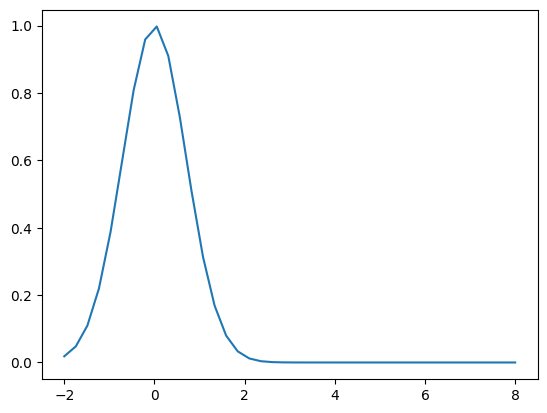

In [35]:
from matplotlib import pyplot
pyplot.plot(x, psi.get())

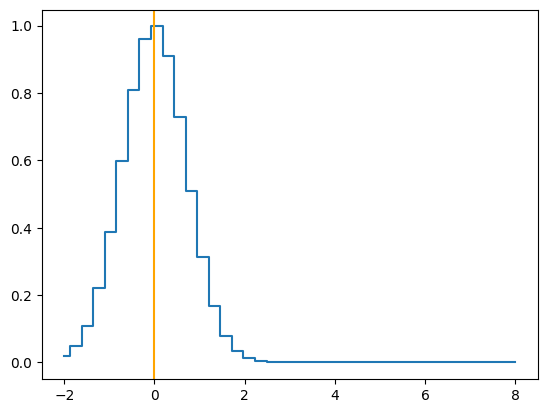

In [36]:
pyplot.step(x, psi.get(), where='mid')
pyplot.axvline(0, color='orange')

In [38]:
from PyMPDATA import Stepper, Solver

solver = Solver(advector=C, advectee=psi, stepper=Stepper(n_dims=1, options=options))
solver.advance(500)


8011.46

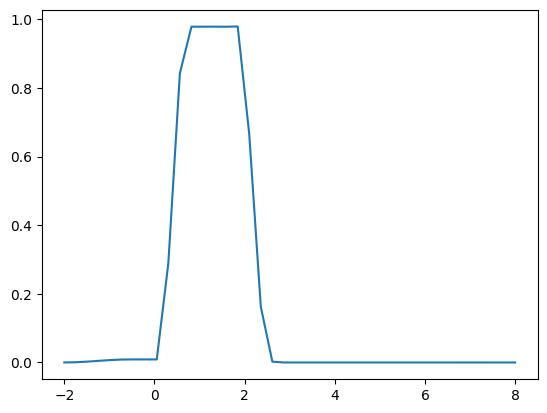

In [39]:
pyplot.plot(x, psi.get())

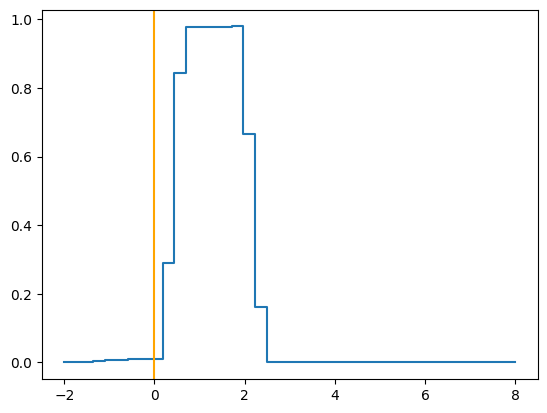

In [40]:
pyplot.step(x, psi.get(), where='mid')
pyplot.axvline(0, color='orange')